# 01 — Dataset Verification & Exploratory Analysis

**Objective:** Understand the structure, and contents of Tableau's Sample Superstore dataset before conducting data quality checks or business analysis.

**Source:** Tableau Sample Superstore (`sample-superstore.xls`)

### 1. Import libraries and locate data files

In [2]:
# Import necessary libraries

from pathlib import Path
import pandas as pd
import xlrd

print("Pandas version:", pd.__version__)
print("xlrd version:", xlrd.__version__)

Pandas version: 2.2.3
xlrd version: 2.0.2


In [3]:
# Resolve the repository root, whether the notebook runs
# from the repository directory or its notebooks/ subfolder.
current_dir = Path.cwd()

if (current_dir / "data" / "raw").exists():
    project_root = current_dir
elif (current_dir.parent / "data" / "raw").exists():
    project_root = current_dir.parent
else:
    raise FileNotFoundError(
        "Cannot locate the project's data/raw directory."
    )

data_path = project_root / "data" / "raw" / "sample-superstore.xls"

print("Source:", data_path)
print("File exists:", data_path.is_file())

if not data_path.is_file():
    raise FileNotFoundError(f"Dataset not found: {data_path}")


Source: c:\Dev\retail-sales-profitability-dashboard\data\raw\sample-superstore.xls
File exists: True


### 2. Inspect workbook sheets

In [4]:
# Open the Excel workbook.
workbook = pd.ExcelFile(data_path, engine="xlrd")

print("Workbook sheets:")
for sheet in workbook.sheet_names:
    print(f" - {sheet}")

# Inspect the dimensions of each sheet.
sheet_summary = []

for sheet_name in workbook.sheet_names:
    df_sheet = pd.read_excel(workbook, sheet_name=sheet_name)

    sheet_summary.append({
        "Sheet": sheet_name,
        "Rows": df_sheet.shape[0],
        "Columns": df_sheet.shape[1]
    })

sheet_summary_df = pd.DataFrame(sheet_summary)
display(sheet_summary_df)

Workbook sheets:
 - Orders
 - People
 - Returns


,Sheet,Rows,Columns
0,Orders,10194,21
1,People,4,2
2,Returns,296,2


In [5]:
# Initial inspection. Select the first worksheet
selected_sheet = workbook.sheet_names[0]

df = pd.read_excel(workbook, sheet_name=selected_sheet)

print("Selected sheet:", selected_sheet)

# Print column names and dtypes
print("\nColumn data types:")
display(df.dtypes.to_frame(name="Data Type"))

Selected sheet: Orders

Column data types:


,Data Type
Row ID,int64
Order ID,object
Order Date,datetime64[ns]
Ship Date,datetime64[ns]
Ship Mode,object
Customer ID,object
Customer Name,object
Segment,object
Country/Region,object
City,object


In [6]:
print("\nFirst five records:")
df.head()


First five records:


,Row ID,Order ID,Order Date,Ship Date,Ship Mode,Customer ID,Customer Name,Segment,Country/Region,City,...,Postal Code,Region,Product ID,Category,Sub-Category,Product Name,Sales,Quantity,Discount,Profit
0,1,US-2023-103800,2023-01-03,2023-01-07,Standard Class,DP-13000,Darren Powers,Consumer,United States,Houston,...,77095,Central,OFF-PA-10000174,Office Supplies,Paper,"Message Book, Wirebound, Four 5 1/2"" X 4"" Form...",16.448,2,0.2,5.5512
1,2,US-2023-112326,2023-01-04,2023-01-08,Standard Class,PO-19195,Phillina Ober,Home Office,United States,Naperville,...,60540,Central,OFF-BI-10004094,Office Supplies,Binders,GBC Standard Plastic Binding Systems Combs,3.540,2,0.8,-5.4870
2,3,US-2023-112326,2023-01-04,2023-01-08,Standard Class,PO-19195,Phillina Ober,Home Office,United States,Naperville,...,60540,Central,OFF-LA-10003223,Office Supplies,Labels,Avery 508,11.784,3,0.2,4.2717
3,4,US-2023-112326,2023-01-04,2023-01-08,Standard Class,PO-19195,Phillina Ober,Home Office,United States,Naperville,...,60540,Central,OFF-ST-10002743,Office Supplies,Storage,SAFCO Boltless Steel Shelving,272.736,3,0.2,-64.7748
4,5,US-2023-141817,2023-01-05,2023-01-12,Standard Class,MB-18085,Mick Brown,Consumer,United States,Philadelphia,...,19143,East,OFF-AR-10003478,Office Supplies,Art,Avery Hi-Liter EverBold Pen Style Fluorescent ...,19.536,3,0.2,4.8840


## II. Supporting Tables: People and Returns

**Objective:** Examine the supporting worksheets to determine whether they can enhance the dashboard.

In [7]:
# Load the supporting worksheets.
people = pd.read_excel(workbook, sheet_name="People")
returns = pd.read_excel(workbook, sheet_name="Returns")

for name, table in [("People", people), ("Returns", returns)]:
    print(f"\n{name.upper()}")
    print("Shape:", table.shape)
    print("Columns:", table.columns.tolist())
    print("Data types:")
    display(table.dtypes.to_frame("Data Type"))
    display(table.head())



PEOPLE
Shape: (4, 2)
Columns: ['Regional Manager', 'Region']
Data types:


,Data Type
Regional Manager,object
Region,object


,Regional Manager,Region
0,Sadie Pawthorne,West
1,Chuck Magee,East
2,Roxanne Rodriguez,Central
3,Fred Suzuki,South



RETURNS
Shape: (296, 2)
Columns: ['Order ID', 'Returned']
Data types:


,Data Type
Order ID,object
Returned,object


,Order ID,Returned
0,US-2023-100762,Yes
1,US-2023-100867,Yes
2,US-2023-102652,Yes
3,US-2023-103373,Yes
4,US-2023-103744,Yes


In [8]:
# Check relationship keys

for name, table in [("People", people), ("Returns", returns)]:
    common_columns = sorted(
        set(df.columns).intersection(table.columns)
    )

    print(f"{name} common columns with Orders:")
    print(common_columns)


People common columns with Orders:
['Region']
Returns common columns with Orders:
['Order ID']


## III. Dataset Coverage and Record Granularity

**Objective:** Identify the period covered by the Orders data and measure the number of distinct business entities.

In [9]:
print("DATASET COVERAGE")
print("-" * 45)

print("First order date:", df["Order Date"].min())
print("Last order date:", df["Order Date"].max())

print("\nBUSINESS ENTITY COUNTS")
print("-" * 45)

summary = {
    "Order lines": len(df),
    "Distinct orders": df["Order ID"].nunique(),
    "Distinct customers": df["Customer ID"].nunique(),
    "Distinct products": df["Product ID"].nunique(),
    "Regions": df["Region"].nunique(),
    "States": df["State/Province"].nunique(),
    "Categories": df["Category"].nunique(),
    "Sub-categories": df["Sub-Category"].nunique(),
}

display(
    pd.DataFrame(
        summary.items(),
        columns=["Metric", "Value"]
    )
)


DATASET COVERAGE
---------------------------------------------
First order date: 2023-01-03 00:00:00
Last order date: 2026-12-30 00:00:00

BUSINESS ENTITY COUNTS
---------------------------------------------


,Metric,Value
0,Order lines,10194
1,Distinct orders,5111
2,Distinct customers,804
3,Distinct products,1862
4,Regions,4
5,States,59
6,Categories,3
7,Sub-categories,17


## IV. Data Quality: Missing Values and Duplicates

**Objective:** Assess completeness and identify potentially duplicated records.

In [10]:
# Missing values

missing_summary = pd.DataFrame({
    "Missing Count": df.isna().sum(),
    "Missing %": df.isna().mean() * 100
})

# Display missing values if any
if missing_summary["Missing Count"].sum() > 0:
    print("Missing values found:")
    display(missing_summary)
else:
    print("No missing values found.")


No missing values found.


In [11]:
# Duplicate records

print("Fully duplicated rows:", df.duplicated().sum())

print(
    "Duplicated Row IDs:",
    df["Row ID"].duplicated().sum()
)

Fully duplicated rows: 0
Duplicated Row IDs: 0


## V. Supporting Table Relationship Integrity

**Objective:** Verify whether the People and Returns worksheets can be safely related to the Orders table. Incorrect database relationships can duplicate financial values and produce misleading metrics.

**Checks:**
- Uniqueness of Region in People.
- Uniqueness of Order ID in Returns.
- Unmatched region identifiers.
- Return records referencing nonexistent orders.

In [12]:
# Check uniqueness of supporting table keys.
print(
    "Duplicate regions in People:",
    people["Region"].duplicated().sum()
)

print(
    "Duplicate Order IDs in Returns:",
    returns["Order ID"].duplicated().sum()
)

# Compare region values.
unmatched_regions = (
    set(df["Region"].dropna())
    - set(people["Region"].dropna())
)

# Compare return identifiers with source orders.
unmatched_returns = (
    set(returns["Order ID"].dropna())
    - set(df["Order ID"].dropna())
)

print("\nUnmatched regions:", unmatched_regions)
print("Unmatched returned orders:", len(unmatched_returns))

if unmatched_returns:
    print("Example unmatched return IDs:")
    print(sorted(unmatched_returns)[:10])


Duplicate regions in People: 0
Duplicate Order IDs in Returns: 0

Unmatched regions: set()
Unmatched returned orders: 0


## VI. Temporal Data Quality

**Objective:** Verify date consistency and determine annual transaction coverage. Invalid dates can distort trend analysis, while incomplete periods can produce misleading comparisons.

**Checks:**
- Orders with shipping dates before order dates.
- Missing order or shipping dates.
- Annual order-line distribution.
- Earliest and latest order dates by year.

In [13]:
print(
    "Ship dates before order dates:",
    (df["Ship Date"] < df["Order Date"]).sum()
)

# Group rows by year and carry out checks
yearly_coverage = (
    df.assign(Year=df["Order Date"].dt.year)
      .groupby("Year")
      .agg(
          Order_Lines=("Row ID", "size"),
          Unique_Orders=("Order ID", "nunique"),
          First_Order=("Order Date", "min"),
          Last_Order=("Order Date", "max")
      )
      .reset_index()
)

display(yearly_coverage)


Ship dates before order dates: 0


,Year,Order_Lines,Unique_Orders,First_Order,Last_Order
0,2023,2051,995,2023-01-03,2023-12-31
1,2024,2130,1053,2024-01-02,2024-12-31
2,2025,2634,1340,2025-01-02,2025-12-31
3,2026,3379,1723,2026-01-01,2026-12-30


## VII. Numerical Data Validation

**Objective:** Identify potentially invalid sales, quantities, and discount values while distinguishing valid business losses from data errors.

Checks:

- Zero or negative sales values.
- Zero or negative quantities.
- Discounts outside the expected 0–1 range.
- Negative profit lines.
- Minimum and maximum numeric values.

In [14]:
# Identify numerical columns
numeric_columns = ["Sales", "Quantity", "Discount", "Profit"]

# Display staristics
display(df[numeric_columns].describe().T)

checks = {
    "Sales <= 0": (df["Sales"] <= 0).sum(),
    "Quantity <= 0": (df["Quantity"] <= 0).sum(),
    "Discount < 0": (df["Discount"] < 0).sum(),
    "Discount > 1": (df["Discount"] > 1).sum(),
    "Negative profit lines": (df["Profit"] < 0).sum()
}

display(
    pd.DataFrame(
        checks.items(),
        columns=["Check", "Count"]
    )
)


,count,mean,std,min,25%,50%,75%,max
Sales,10194.0,228.225854,619.906839,0.444,17.2200,53.91,209.500000,22638.480
Quantity,10194.0,3.791838,2.228317,1.000,2.0000,3.00,5.000000,14.000
Discount,10194.0,0.155385,0.206249,0.000,0.0000,0.20,0.200000,0.800
Profit,10194.0,28.673417,232.465115,-6599.978,1.7608,8.69,29.297925,8399.976


,Check,Count
0,Sales <= 0,0
1,Quantity <= 0,0
2,Discount < 0,0
3,Discount > 1,0
4,Negative profit lines,1901


- Sales: The average order-line sales value is about $228, considerably higher than the median of $53.91. This suggests a right-skewed distribution with some large transactions.

- Profit: The dataset contains substantial positive and negative profit values. Those extreme records may have a meaningful influence on overall profitability.

- Discount: Discounts range from 0% to 80%, making discounting a promising dimension for further investigation.

## Data Quality Assessment — Findings and Decisions

### Summary of Findings

The Orders dataset contains 10,194 order-line records. Initial validation found:

- No reported missing values in Orders.
- No fully duplicated records or duplicate Row IDs.
- No shipping dates preceding order dates.
- No zero or negative sales or quantity values.
- No discounts outside the expected range of 0 to 1.
- No duplicate relationship keys in the People or Returns worksheets.
- No unmatched regions or returned-order identifiers.

The dataset contains **1,901 negative-profit order lines**, representing approximately **18.6%** of all order lines.

### Data Preparation Decisions

1. **Preserve original source data:** The Excel workbook remains unchanged.
2. **Retain negative-profit records:** They represent a meaningful business outcome rather than an established data error.
3. **Preserve financial precision:** Avoid unnecessary rounding during data preparation.
4. **Retain order-line granularity:** One row represents one recorded order line.
5. **Use distinct Order IDs for order counts:** Do not equate order lines with unique customer orders.
6. **Preserve supporting tables:** People and Returns will remain available for database modeling.
7. **Investigate extreme financial observations:** Large sales and profit values will be reviewed during exploratory analysis, rather than automatically excluded.
8. **Document simulated future dates:** The dataset covers January 2023 through December 2026 and contains transactions beyond the project's current calendar date.

### Remaining Verification

- Check for conflicting customer and product attributes where relevant.
- Confirm that order-level attributes are consistent across multiple lines within an order.
- Validate financial KPI totals before database implementation.

### Conclusion

The key analytical priority is to understand the sources and concentration of negative profitability.

# Exploratory Business Analysis

## VIII. Overall Business Performance

**Objective:** Establish baseline financial and operational performance indicators for the entire dataset.These metrics will form the foundation of the executive dashboard. Establishing them independently in Python allows us to validate subsequent SQL and Tableau calculations.

**Metrics:**
- Total Sales
- Total Profit
- Profit Margin
- Distinct Orders
- Average Order Value
- Units Sold

In [15]:
# Baseline financial and operational KPIs
total_sales = df["Sales"].sum()
total_profit = df["Profit"].sum()
total_orders = df["Order ID"].nunique()
total_units = df["Quantity"].sum()

# Calculate Profit Margin and Average Order Value
profit_margin = (
    total_profit / total_sales * 100
    if total_sales != 0 else 0
)

avg_order_value = (
    total_sales / total_orders
    if total_orders != 0 else 0
)

# Create a summary DataFrame for KPIs
kpi_summary = pd.DataFrame({
    "Metric": [
        "Total Sales",
        "Total Profit",
        "Profit Margin (%)",
        "Distinct Orders",
        "Average Order Value",
        "Units Sold"
    ],
    "Value": [
        total_sales,
        total_profit,
        profit_margin,
        total_orders,
        avg_order_value,
        total_units
    ]
})

display(kpi_summary)


,Metric,Value
0,Total Sales,2.326534e+06
1,Total Profit,2.922968e+05
2,Profit Margin (%),1.256361e+01
3,Distinct Orders,5.111000e+03
4,Average Order Value,4.552014e+02
5,Units Sold,3.865400e+04


## IX. Annual Sales and Profitability Trends

**Objective:** Compare yearly sales, profits, profit margins, and order volumes. By comparing financial and operational KPIs over time, we can identify whether commercial performance is improving or deteriorating.

In [16]:
# Annual performance metrics
annual_performance = (
    df.assign(Year=df["Order Date"].dt.year)
    .groupby("Year")
    .agg(
        Sales=("Sales", "sum"),
        Profit=("Profit", "sum"),
        Orders=("Order ID", "nunique"),
        Units=("Quantity", "sum")
    )
    .reset_index()
)

# Calculate Profit Margin and Growth Rates
annual_performance["Profit Margin (%)"] = (
    annual_performance["Profit"]
    / annual_performance["Sales"] * 100
)

annual_performance["Sales Growth (%)"] = (
    annual_performance["Sales"].pct_change() * 100
)

annual_performance["Profit Growth (%)"] = (
    annual_performance["Profit"].pct_change() * 100
)

display(annual_performance.round(2))


,Year,Sales,Profit,Orders,Units,Profit Margin (%),Sales Growth (%),Profit Growth (%)
0,2023,494040.21,51684.30,995,7813,10.46,NaN,NaN
1,2024,472993.03,62020.97,1053,8086,13.11,-4.26,20.00
2,2025,613933.58,82665.20,1340,10018,13.46,29.80,33.29
3,2026,745567.53,95926.35,1723,12737,12.87,21.44,16.04


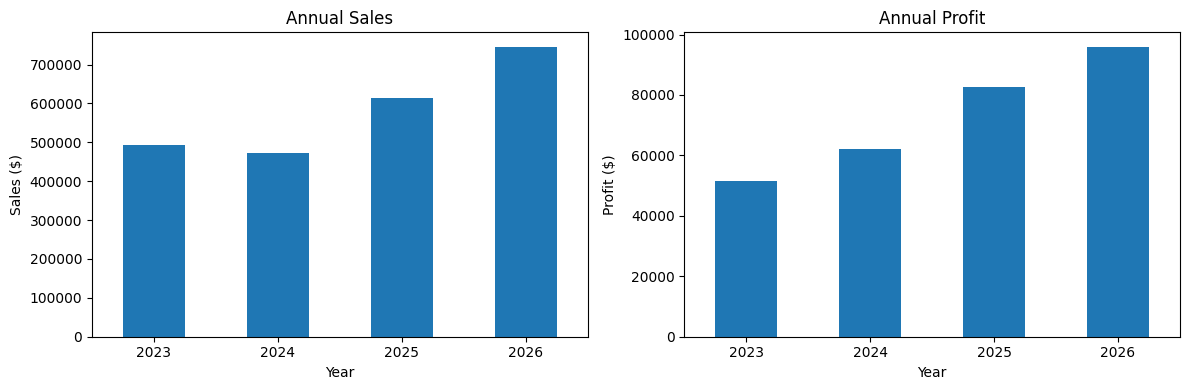

In [23]:
# Visualize annual sales and profit trends

import matplotlib.pyplot as plt

# Create a bar chart for annual sales and profit
fig, axes = plt.subplots(1, 2, figsize=(12, 4))

# Plot annual sales and profit
annual_performance.plot(
    x="Year", y="Sales",
    kind="bar", ax=axes[0],
    legend=False, title="Annual Sales"
)

annual_performance.plot(
    x="Year", y="Profit",
    kind="bar", ax=axes[1],
    legend=False, title="Annual Profit"
)
# Set y-axis labels
axes[0].set_ylabel("Sales ($)")
axes[1].set_ylabel("Profit ($)")

for ax in axes:
    ax.tick_params(axis="x", rotation=0)

plt.tight_layout()
plt.show()


- Sales dropped in 2024, but increased in 2025 and 2026
- Though there was a drop in sales, the company still made profits each year, with each year outperforming the previous one.

## X. Monthly Performance and Seasonality

**Objective:** Examine monthly sales and profitability patterns across the available years. Monthly analysis can reveal seasonal demand, volatile profits, and periods in which sales growth does not translate into stronger profitability.

In [24]:
# Group by month and calculate monthly performance metrics
monthly_performance = (
    df.assign(
        Month=df["Order Date"].dt.to_period("M")
    )
    .groupby("Month")
    .agg(
        Sales=("Sales", "sum"),
        Profit=("Profit", "sum"),
        Orders=("Order ID", "nunique")
    )
    .reset_index()
)
# Set the Month column to timestamp for better visualization
monthly_performance["Month"] = (
    monthly_performance["Month"].dt.to_timestamp()
)

# Calculate Profit Margin
monthly_performance["Profit Margin (%)"] = (
    monthly_performance["Profit"]
    / monthly_performance["Sales"] * 100
)

display(monthly_performance.head(12))


,Month,Sales,Profit,Orders,Profit Margin (%)
0,2023-01-01,14518.0550,2539.3907,33,17.491260
1,2023-02-01,4519.8920,862.3084,28,19.078075
2,2023-03-01,56933.9090,693.4499,72,1.217991
3,2023-04-01,28295.3450,3488.8352,66,12.330068
4,2023-05-01,26319.7670,3196.3918,72,12.144453
5,2023-06-01,34669.4796,4999.7594,67,14.421213
6,2023-07-01,33946.3930,-841.4826,65,-2.478857
7,2023-08-01,28918.3385,5765.2250,75,19.936225
8,2023-09-01,82670.4288,8593.6302,134,10.395047
9,2023-10-01,32413.3390,3469.1749,81,10.702924


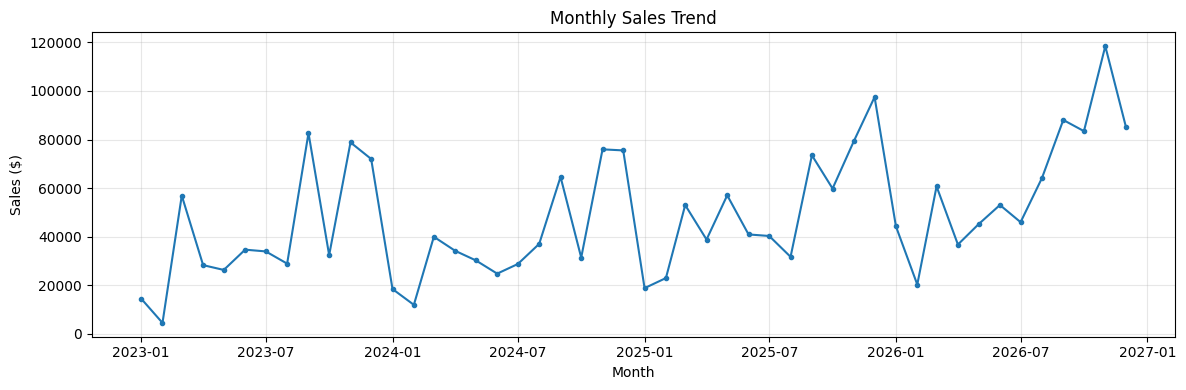

In [22]:
# Monthly trend visualization
plt.figure(figsize=(12, 4))

plt.plot(
    monthly_performance["Month"],
    monthly_performance["Sales"],
    marker="o",
    markersize=3
)

plt.title("Monthly Sales Trend")
plt.xlabel("Month")
plt.ylabel("Sales ($)")
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()


## Overall Performance — Key Findings

### Finding 1: Revenue and Profit Growth Are Not Always Aligned

The dataset generated approximately $2.33 million in sales and $292,297 in recorded profit, representing an overall profit margin of approximately 12.56%.

Annual analysis revealed differences between revenue growth and profit growth.

In 2024, sales declined by 4.26%, but profit increased by approximately 20%. In 2026, sales increased by 21.44%, while profit grew by only 16.04%.

These patterns suggest that changes in sales volume alone do not fully explain profitability.

### Finding 2: Profit Margin Declined in 2026

The annual profit margin reached approximately 13.46% in 2025 before declining to 12.87% in 2026.

Although total revenue and profit continued increasing, the lower margin indicates weaker profitability relative to sales.

Further analysis is required to identify possible contributing factors.

### Finding 3: Monthly Performance Is Volatile

Monthly sales vary considerably across the dataset.

Several large sales months appear toward the final quarter of the year, suggesting possible seasonal patterns that require further examination.

July 2023 recorded approximately $33,946 in sales but a net loss of $841, demonstrating that positive sales do not guarantee profitability.

### Analytical Questions for Subsequent Investigation

1. Which product categories and subcategories contribute most to sales and profits?
2. Are negative-profit transactions concentrated in particular regions?
3. Do discount patterns differ between profitable and unprofitable sales?
4. What explains the reduction in profit margin during 2026?
5. Are there consistent seasonal trends across the four reporting years?

### Dashboard Implications

The Executive Performance Overview should include:

- KPI cards for Sales, Profit, Margin, and Orders.
- Annual or monthly revenue and profit trends.
- Year-over-year performance comparisons.
- Interactive filters for reporting periods and business segments.

The Profitability Diagnostics dashboard should help users investigate margin deterioration and identify business areas contributing to losses.

## Product & Geographic Profitability

### XI. Product Category Performance

**Objective:** Compare sales, profit, profit margin, and order volume across product categories. Category comparisons help identify opportunities for improved commercial performance.

In [25]:
# Group by category and calculate performance metrics
category_performance = (
    df.groupby("Category")
    .agg(
        Sales=("Sales", "sum"),
        Profit=("Profit", "sum"),
        Orders=("Order ID", "nunique"),
        Units=("Quantity", "sum")
    )
    .reset_index()
)

# Calculate Profit Margin
category_performance["Profit Margin (%)"] = (
    category_performance["Profit"]
    / category_performance["Sales"] * 100
)

# Sort by Sales in descending order
category_performance = category_performance.sort_values(
    "Sales", ascending=False
)

display(category_performance.round(2))


,Category,Sales,Profit,Orders,Units,Profit Margin (%)
2,Technology,839893.28,146543.38,1560,7017,17.45
0,Furniture,754747.76,19730.00,1819,8369,2.61
1,Office Supplies,731893.31,126023.44,3812,23268,17.22


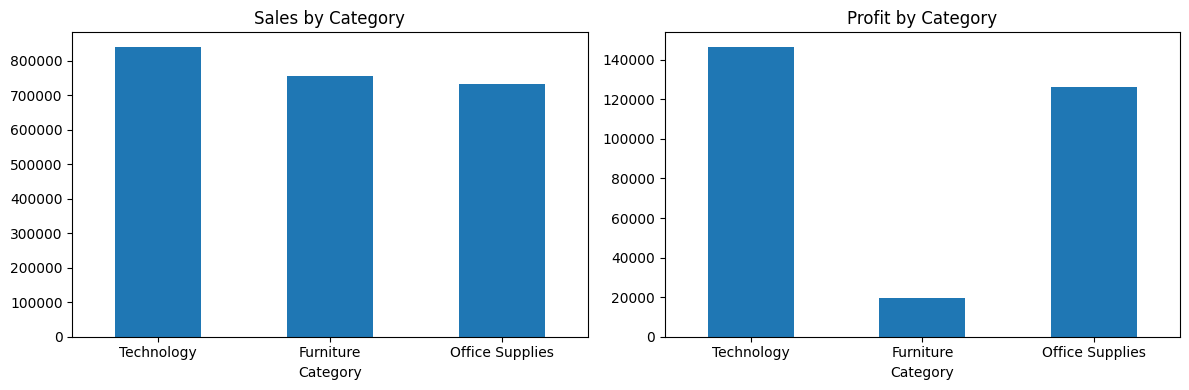

In [ ]:
# Visualize category performance
fig, axes = plt.subplots(1, 2, figsize=(12, 4))

# Sales bar chart
category_performance.plot.bar(
    x="Category", y="Sales",
    ax=axes[0], legend=False,
    title="Sales by Category"
)

# Profit bar chart
category_performance.plot.bar(
    x="Category", y="Profit",
    ax=axes[1], legend=False,
    title="Profit by Category"
)

for ax in axes:
    ax.tick_params(axis="x", rotation=0)

plt.tight_layout()
plt.show()


### XII. Subcategory Profitability

**Objective:** Identify the highest- and lowest-performing product subcategories. More detailed analysis is needed to identify actionable profitability issues.

In [27]:
# Group by sub-category and calculate performance metrics
subcategory_performance = (
    df.groupby(["Category", "Sub-Category"])
    .agg(
        Sales=("Sales", "sum"),
        Profit=("Profit", "sum"),
        Orders=("Order ID", "nunique")
    )
    .reset_index()
)

subcategory_performance["Profit Margin (%)"] = (
    subcategory_performance["Profit"]
    / subcategory_performance["Sales"] * 100
)

subcategory_performance = subcategory_performance.sort_values(
    "Profit", ascending=True
)

display(subcategory_performance.round(2))


,Category,Sub-Category,Sales,Profit,Orders,Profit Margin (%)
3,Furniture,Tables,208020.18,-17753.21,314,-8.53
0,Furniture,Bookcases,115361.20,-3632.07,228,-3.15
12,Office Supplies,Supplies,46725.50,-1171.39,189,-2.51
8,Office Supplies,Fasteners,8532.24,2428.64,226,28.46
15,Technology,Machines,189925.03,3461.98,114,1.82
9,Office Supplies,Labels,12695.04,5572.78,348,43.90
5,Office Supplies,Art,27659.01,6653.20,756,24.05
7,Office Supplies,Envelopes,16528.36,6988.02,251,42.28
2,Furniture,Furnishings,95598.13,13891.74,919,14.53
4,Office Supplies,Appliances,108213.18,18329.48,459,16.94


### XIV. Regional Sales and Profitability

**Objective:** Compare sales, profit, profit margins, and order volumes across geographic regions. Regional comparisons can reveal uneven performance and help management prioritize areas requiring attention.

In [ ]:
# Group by region and calculate performance metrics
regional_performance = (
    df.groupby("Region")
    .agg(
        Sales=("Sales", "sum"),
        Profit=("Profit", "sum"),
        Orders=("Order ID", "nunique")
    )
    .reset_index()
)
# Calculate Profit Margin
regional_performance["Profit Margin (%)"] = (
    regional_performance["Profit"]
    / regional_performance["Sales"] * 100
)
# Sort by Profit in descending order
regional_performance = regional_performance.sort_values(
    "Profit", ascending=False
)

display(regional_performance.round(2))


,Region,Sales,Profit,Orders,Profit Margin (%)
3,West,739813.61,110798.82,1635,14.98
1,East,691828.17,94883.26,1475,13.71
2,South,391721.90,46749.43,822,11.93
0,Central,503170.67,39865.31,1179,7.92


## Product and Geographic Performance Findings

### Finding 1: Furniture Generates Revenue but Contributes Little Profit

Furniture generated approximately $754,748 in sales but only $19,730 in profit, producing a margin of 2.61%.

Although Furniture accounted for approximately 32.4% of total sales, it contributed only about 6.8% of total profit. This identifies Furniture as a priority for profitability investigation.

### Finding 2: Tables, Bookcases, and Supplies Are Unprofitable

Three subcategories recorded negative aggregate profits:

- Tables: -$17,753 (margin: -8.53%)
- Bookcases: -$3,632 (margin: -3.15%)
- Supplies: -$1,171 (margin: -2.51%)

Machines also require attention because their profit margin is only 1.82%, despite generating approximately $189,925 in sales.

### Finding 3: Technology Contains Strong Profit Contributors

Technology generated the highest category-level profit, approximately $146,543, with a profit margin of 17.45%.

Copiers generated approximately $56,094 in profit at a margin of 37.21%, making them an interesting comparison with the unprofitable Tables subcategory.

### Finding 4: Central Has the Lowest Regional Margin

The West region achieved the highest profit margin at 14.98%, followed by East (13.71%), South (11.93%), and Central (7.92%).

Central generated more revenue than South but less profit. Further analysis is needed to determine whether Central's lower profitability is associated with its product mix, discounting patterns, or other factors.

### Questions for Further Investigation

1. Are Furniture losses concentrated in specific regions?
2. Do Tables and Bookcases receive unusually high discounts?
3. Which customer segments contribute most to negative profitability?
4. Does the profitability of the same subcategory differ significantly across regions?
5. Are regional profitability gaps becoming wider or narrower over time?

### Dashboard Implications

The Profitability Diagnostics dashboard should support:

- Category and subcategory margin comparisons.
- Identification of negative-profit product groups.
- Region-by-category drill-downs.
- Discount and profitability analysis.
- Investigation of product groups with high sales but low margins.

**Important:** These results are descriptive. They identify areas for investigation but do not establish the causes of poor profitability.

## Discounts, Returns & Customer Segments

### XV. Regional and Category Profitability

**Objective:** Examine profitability at the intersection of geographic region and product category.

**Questions:**
- Is Furniture unprofitable in every region?
- Does Central's weak profitability occur across all categories?
- Which region-category combinations generate the largest losses?

In [29]:
# Group by region and category, and calculate performance metrics
region_category = (
    df.groupby(["Region", "Category"])
    .agg(
        Sales=("Sales", "sum"),
        Profit=("Profit", "sum"),
        Orders=("Order ID", "nunique")
    )
    .reset_index()
)
# Calculate Profit Margin
region_category["Profit Margin (%)"] = (
    region_category["Profit"]
    / region_category["Sales"] * 100
)
# Sort by Profit
display(region_category.sort_values("Profit").round(2))


,Region,Category,Sales,Profit,Orders,Profit Margin (%)
0,Central,Furniture,164537.65,-2802.21,407,-1.70
3,East,Furniture,212231.70,3444.74,521,1.62
6,South,Furniture,117298.68,6771.21,278,5.77
1,Central,Office Supplies,168216.71,8970.08,884,5.33
9,West,Furniture,260679.73,12316.25,613,4.72
7,South,Office Supplies,125651.31,19986.39,619,15.91
8,South,Technology,148771.91,19991.83,255,13.44
2,Central,Technology,170416.31,33697.43,356,19.77
4,East,Office Supplies,211658.40,42996.74,1132,20.31
11,West,Technology,252766.99,44412.34,498,17.57


In [32]:
# Create a pivot table for profit margin by region and category
margin_matrix = region_category.pivot(
    index="Region",
    columns="Category",
    values="Profit Margin (%)"
)

display(
    margin_matrix.style
    .format("{:.2f}%")
    .background_gradient(
        cmap="RdYlGn",
        axis=None,
        vmin=-15,
        vmax=25
    )
)


Category,Furniture,Office Supplies,Technology
Region,,,
Central,-1.70%,5.33%,19.77%
East,1.62%,20.31%,18.08%
South,5.77%,15.91%,13.44%
West,4.72%,23.89%,17.57%


### XVI. Discount and Profitability Analysis

**Objective:** Compare sales, profits, and margins across discount levels. These comparisons are descriptive. They cannot establish that discounts caused negative profitability.

In [33]:
# Group by discount and calculate performance metrics
discount_performance = (
    df.groupby("Discount")
    .agg(
        Order_Lines=("Row ID", "count"),
        Sales=("Sales", "sum"),
        Profit=("Profit", "sum")
    )
    .reset_index()
)
# Calculate Profit Margin
discount_performance["Profit Margin (%)"] = (
    discount_performance["Profit"]
    / discount_performance["Sales"] * 100
)
# Calculate the number of negative profit lines for each discount level
discount_performance["Negative Profit Lines"] = (
    df.assign(Is_Loss=df["Profit"] < 0)
    .groupby("Discount")["Is_Loss"]
    .sum()
    .values
)
# Calculate Loss Line Rate (%) for each discount level
discount_performance["Loss Line Rate (%)"] = (
    discount_performance["Negative Profit Lines"]
    / discount_performance["Order_Lines"] * 100
)

display(discount_performance.round(2))


,Discount,Order_Lines,Sales,Profit,Profit Margin (%),Negative Profit Lines,Loss Line Rate (%)
0,0.00,4925,1105323.79,326718.59,29.56,0,0.00
1,0.10,96,54952.50,9099.97,16.56,4,4.17
2,0.15,52,27558.52,1418.99,5.15,17,32.69
3,0.20,3706,773939.40,91079.95,11.77,510,13.76
4,0.30,230,104474.07,-10513.45,-10.06,211,91.74
5,0.32,27,14493.46,-2391.14,-16.50,27,100.00
6,0.40,207,116497.76,-23086.37,-19.82,181,87.44
7,0.45,11,5484.97,-2493.11,-45.45,11,100.00
8,0.50,66,58918.54,-20506.43,-34.80,66,100.00
9,0.60,149,7105.94,-6164.35,-86.75,149,100.00


## Regional and Discount Analysis Findings

### Finding 1: Central Has Concentrated Profitability Weaknesses

Central Furniture generated approximately $164,538 in sales but recorded a net loss of $2,802, representing a -1.70% profit margin.

Central Office Supplies also underperformed, recording a margin of only 5.33%, substantially below the corresponding margins in East, South, and West.

In contrast, Central Technology achieved a 19.77% margin, indicating that profitability problems are not uniform across the region.

### Finding 2: Higher Discount Levels Are Associated with Lower Profitability

Order lines without discounts generated a 29.56% aggregate profit margin, with no negative-profit lines recorded.

At a 20% discount, profit margin declined to 11.77%.

At a 30% discount, aggregate profit margin became negative (-10.06%), and approximately 91.74% of order lines recorded losses.

Every recorded order line discounted at 50%, 60%, 70%, or 80% generated negative profit.

These findings indicate a strong descriptive association between discount levels and profitability.

### Finding 3: Profitability Patterns Require More Granular Investigation

The observed relationship between discounts and losses may partly reflect the types of products, customer segments, or regions receiving discounts.

### Next Analytical Questions

1. Which categories and regions have the highest exposure to large discounts?
2. Do some product categories remain profitable even when discounted?
3. Are discount patterns associated with the weak margins observed in Central?
4. How do returns and customer segments relate to overall profitability?

## Investigate high-discount exposure

### VXII. High-Discount Exposure by Category and Region

**Objective:** Identify the product categories and regions most exposed to high-discount transactions For this analysis, we'll classify discounts of 30% or more as high discounts.

**Metrics:**
- Number of high-discount order lines.
- Percentage of order lines receiving high discounts.
- Sales associated with high-discount lines.
- Aggregate profit from high-discount lines.
- Profit margin of high-discount sales.

In [ ]:
# Create an analysis copy without modifying the source data.
discount_analysis = df.copy()

# Exploratory classification.
discount_analysis["High Discount"] = (
    discount_analysis["Discount"] >= 0.30
)
# Filter the DataFrame to include only high-discount sales lines.
discount_analysis["High Discount Sales"] = (
    discount_analysis["Sales"].where(
        discount_analysis["High Discount"], 0
    )
)
# Filter the DataFrame to include only high-discount profit lines.
discount_analysis["High Discount Profit"] = (
    discount_analysis["Profit"].where(
        discount_analysis["High Discount"], 0
    )
)

print("High-discount lines:",
      discount_analysis["High Discount"].sum())


High-discount lines: 1415


In [35]:
# Group by category and calculate high-discount performance metrics
category_discount = (
    discount_analysis.groupby("Category")
    .agg(
        Order_Lines=("Row ID", "count"),
        High_Discount_Lines=("High Discount", "sum"),
        High_Discount_Sales=("High Discount Sales", "sum"),
        High_Discount_Profit=("High Discount Profit", "sum")
    )
    .reset_index()
)
# Calculate High Discount Rate (%) and High Discount Margin (%)
category_discount["High Discount Rate (%)"] = (
    category_discount["High_Discount_Lines"]
    / category_discount["Order_Lines"] * 100
)

category_discount["High Discount Margin (%)"] = (
    category_discount["High_Discount_Profit"]
    / category_discount["High_Discount_Sales"]
    * 100
)

display(
    category_discount.sort_values(
        "High Discount Rate (%)", ascending=False
    ).round(2)
)


,Category,Order_Lines,High_Discount_Lines,High_Discount_Sales,High_Discount_Profit,High Discount Rate (%),High Discount Margin (%)
0,Furniture,2201,555,196423.44,-54956.29,25.22,-27.98
1,Office Supplies,6128,689,40240.45,-47306.24,11.24,-117.56
2,Technology,1865,171,128096.26,-33758.16,9.17,-26.35


In [36]:
# Examine regional exposure to high-discount sales and profit

# Group by region and calculate high-discount performance metrics
region_discount = (
    discount_analysis.groupby("Region")
    .agg(
        Order_Lines=("Row ID", "count"),
        High_Discount_Lines=("High Discount", "sum"),
        High_Discount_Sales=("High Discount Sales", "sum"),
        High_Discount_Profit=("High Discount Profit", "sum")
    )
    .reset_index()
)
# Calculate High Discount Rate (%) and High Discount Margin (%)
region_discount["High Discount Rate (%)"] = (
    region_discount["High_Discount_Lines"]
    / region_discount["Order_Lines"] * 100
)

region_discount["High Discount Margin (%)"] = (
    region_discount["High_Discount_Profit"]
    / region_discount["High_Discount_Sales"]
    * 100
)

display(
    region_discount.sort_values(
        "High Discount Rate (%)", ascending=False
    ).round(2)
)


,Region,Order_Lines,High_Discount_Lines,High_Discount_Sales,High_Discount_Profit,High Discount Rate (%),High Discount Margin (%)
0,Central,2335,647,129193.20,-52444.23,27.71,-40.59
1,East,2986,479,147801.30,-42681.28,16.04,-28.88
2,South,1620,171,70716.99,-24880.48,10.56,-35.18
3,West,3253,118,17048.66,-16014.69,3.63,-93.94


## High-Discount Exposure Findings

### Finding 1: Furniture Has the Greatest High-Discount Exposure by Line Rate

Furniture has 555 order lines discounted by at least 30%, representing 25.22% of its order lines.

These high-discount lines generated approximately $196,423 in sales and a combined loss of $54,956.

Furniture also has the lowest overall category margin, making it a priority for further investigation.

### Finding 2: Central Has the Highest Regional High-Discount Exposure

Central has 647 high-discount lines, representing 27.71% of its recorded order lines.

High-discount sales in Central generated an aggregate loss of approximately $52,444.

Central also has the lowest overall regional profit margin, at 7.92%.

These findings suggest a relationship worth investigating between regional discount exposure and profitability.

### Finding 3: High-Discount Losses Are Financially Material

Across all categories, 1,415 order lines received discounts of at least 30%, representing approximately 13.88% of all order lines.

These lines generated approximately $364,760 in sales and an aggregate loss of $136,021.

The high-discount grouping is an exploratory classification, not an established policy threshold.

## Customer Segments and Returns

### VXIII. Customer Segment Performance

**Objective:** Compare revenue, profitability, and order activity across customer segments.
Different customer groups may generate different revenue contributions and profit margins. Understanding these differences can help management prioritize further investigation.

In [37]:
# Group by segment and calculate performance metrics
segment_performance = (
    df.groupby("Segment")
    .agg(
        Sales=("Sales", "sum"),
        Profit=("Profit", "sum"),
        Orders=("Order ID", "nunique"),
        Units=("Quantity", "sum")
    )
    .reset_index()
)

segment_performance["Profit Margin (%)"] = (
    segment_performance["Profit"]
    / segment_performance["Sales"] * 100
)

segment_performance["Average Order Value"] = (
    segment_performance["Sales"]
    / segment_performance["Orders"]
)

display(
    segment_performance.sort_values(
        "Sales", ascending=False
    ).round(2)
)


,Segment,Sales,Profit,Orders,Units,Profit Margin (%),Average Order Value
0,Consumer,1170659.79,136371.45,2628,19844,11.65,445.46
1,Corporate,715806.13,94249.64,1552,11898,13.17,461.22
2,Home Office,440068.43,61675.73,931,6912,14.02,472.68


### XIX. Returns and Profitability

**Objective:** Compare returned and non-returned orders and investigate whether return status is associated with differences in profitability.

In [38]:

# Work on a copy, preserving the original Orders data.
returns_analysis = df.copy()

# Identify returned orders by checking if the Order ID exists in the Returns table.
returned_ids = set(returns["Order ID"].dropna())

returns_analysis["Is Returned"] = (
    returns_analysis["Order ID"].isin(returned_ids)
)

# Display the number of distinct returned orders and total distinct orders.
print(
    "Distinct returned orders:",
    returns_analysis.loc[
        returns_analysis["Is Returned"], "Order ID"
    ].nunique()
)

print(
    "Total distinct orders:",
    returns_analysis["Order ID"].nunique()
)


Distinct returned orders: 296
Total distinct orders: 5111


In [39]:
# compare returned vs non-returned orders

# Group by return status and calculate performance metrics
returns_summary = (
    returns_analysis.groupby("Is Returned")
    .agg(
        Orders=("Order ID", "nunique"),
        Order_Lines=("Row ID", "count"),
        Sales=("Sales", "sum"),
        Profit=("Profit", "sum")
    )
    .reset_index()
)

returns_summary["Profit Margin (%)"] = (
    returns_summary["Profit"]
    / returns_summary["Sales"] * 100
)

total_orders = returns_summary["Orders"].sum()

returns_summary["Share of Orders (%)"] = (
    returns_summary["Orders"] / total_orders * 100
)

display(returns_summary.round(2))


,Is Returned,Orders,Order_Lines,Sales,Profit,Profit Margin (%),Share of Orders (%)
0,False,4815,9394,2146030.08,269064.45,12.54,94.21
1,True,296,800,180504.28,23232.36,12.87,5.79


In [40]:
# Return incidence by category

# Group by category and calculate return performance metrics
category_returns = (
    returns_analysis.groupby("Category")
    .agg(
        Orders=("Order ID", "nunique"),
        Returned_Orders=(
            "Order ID",
            lambda ids: ids[ids.isin(returned_ids)].nunique()
        )
    )
    .reset_index()
)

category_returns["Return Order Rate (%)"] = (
    category_returns["Returned_Orders"]
    / category_returns["Orders"] * 100
)

display(
    category_returns.sort_values(
        "Return Order Rate (%)", ascending=False
    ).round(2)
)


,Category,Orders,Returned_Orders,Return Order Rate (%)
2,Technology,1560,123,7.88
0,Furniture,1819,136,7.48
1,Office Supplies,3812,234,6.14


##  Customer Segments and Returns — Findings

### Finding 1: Consumer Generates the Most Revenue but Has the Lowest Segment Margin

The Consumer segment generated approximately $1.17 million in sales, representing 50.3% of total revenue.

However, Consumer recorded the lowest profit margin among the three customer segments, at 11.65%.

Home Office generated the highest margin (14.02%) and average order value ($472.68), despite having the smallest revenue contribution.

### Finding 2: Approximately 5.79% of Orders Are Flagged as Returned

Of 5,111 distinct orders, 296 are identified in the Returns worksheet.

Orders flagged as returned account for approximately $180,504 in original recorded sales and $23,232 in recorded profit.

These values do not represent refunded revenue or post-return profitability.

### Finding 3: Technology Has the Highest Return-Flagged Order Incidence

Technology has a 7.88% return-flagged order incidence, followed by Furniture (7.48%) and Office Supplies (6.14%).

Because one order may contain multiple categories, these measures do not represent product-specific return rates.

**Conclusion:** Customer segmentation and return flags provide useful supporting context, but the project's strongest analytical focus remains product profitability and discount exposure.

## XX. Order-Level Attribute Consistency

**Objective:** Verify that order-level attributes remain consistent across records sharing the same Order ID. Order-level metrics depend on correctly identifying individual customer orders. Conflicting attributes within an order could cause incorrect customer counts, segment analysis, or reporting-period attribution.

In [41]:
# Check for conflicting order-level attributes
order_attributes = [
    "Customer ID",
    "Order Date",
    "Segment"
]
# Check for consistency of order-level attributes across rows with the same Order ID.
consistency = (
    df.groupby("Order ID")[order_attributes]
    .nunique(dropna=False)
)
# Identify orders with conflicting attributes (more than one unique value for any attribute).
conflicting_orders = (
    consistency.gt(1).any(axis=1)
)

print(
    "Orders with conflicting attributes:",
    conflicting_orders.sum()
)

if conflicting_orders.any():
    display(
        consistency.loc[conflicting_orders].head(10)
    )
else:
    print("All checked order-level attributes are consistent.")


Orders with conflicting attributes: 2


,Customer ID,Order Date,Segment
Order ID,,,
CA-2025-121465,4,1,1
CA-2026-130494,4,1,1


### XXI. Product Identifier Consistency

**Objective:** Determine whether product identifiers consistently correspond to product attributes. Determine whether the dataset supports an unambiguous Product ID-to-product attribute relationship.

In [42]:
# Check for conflicting product-level attributes
product_attributes = [
    "Product Name",
    "Category",
    "Sub-Category"
]

# Check for consistency of product-level attributes across rows with the same Product ID.
product_consistency = (
    df.groupby("Product ID")[product_attributes]
    .nunique(dropna=False)
)
# Identify products with conflicting attributes (more than one unique value for any attribute).
conflicting_products = (
    product_consistency.gt(1).any(axis=1)
)

print(
    "Product IDs with conflicting attributes:",
    conflicting_products.sum()
)

if conflicting_products.any():
    display(
        product_consistency.loc[
            conflicting_products
        ].head(10)
    )
else:
    print("All checked product attributes are consistent.")


Product IDs with conflicting attributes: 32


,Product Name,Category,Sub-Category
Product ID,,,
FUR-BO-10002213,2,1,1
FUR-CH-10001146,2,1,1
FUR-FU-10001473,2,1,1
FUR-FU-10004017,2,1,1
FUR-FU-10004091,2,1,1
FUR-FU-10004270,2,1,1
FUR-FU-10004848,2,1,1
FUR-FU-10004864,2,1,1
OFF-AP-10000576,2,1,1


## 27. Investigation of Identifier Conflicts

**Objective:** Examine the order and product identifiers that map to conflicting attributes. Identifier inconsistencies may affect database keys, joins, product aggregation, and customer-level analytics.

**Investigation questions:**

1. Do conflicting Order IDs represent different customers sharing the same identifier?
2. Are the conflicting product names simple naming variations or genuinely different products?
3. Can the records be retained without compromising the intended dashboard metrics?
4. What constraints should be applied in the analytical database?

In [43]:
# Display details of orders with conflicting attributes
conflicting_order_ids = consistency.index[
    conflicting_orders
]

order_conflict_details = (
    df.loc[
        df["Order ID"].isin(conflicting_order_ids),
        [
            "Row ID",
            "Order ID",
            "Order Date",
            "Customer ID",
            "Customer Name",
            "Segment",
            "Product ID",
            "Sales",
            "Profit"
        ]
    ]
    .sort_values(["Order ID", "Row ID"])
)

display(order_conflict_details)


,Row ID,Order ID,Order Date,Customer ID,Customer Name,Segment,Product ID,Sales,Profit
5009,5010,CA-2025-121465,2025-06-12,HO-15234,Harry Olson,Consumer,FUR-CH-10001270,140.670,54.8613
5010,5011,CA-2025-121465,2025-06-12,HO-15233,Harry Olson,Consumer,FUR-CH-10004495,19.680,6.8880
5011,5012,CA-2025-121465,2025-06-12,HO-15232,Harry Olson,Consumer,OFF-AR-10003696,70.464,22.9008
5012,5013,CA-2025-121465,2025-06-12,HO-15231,Harry Olson,Consumer,OFF-BI-10002414,310.120,80.6312
7191,7192,CA-2026-130494,2026-03-16,HO-15234,Harry Olson,Consumer,FUR-CH-10001270,140.670,54.8613
7192,7193,CA-2026-130494,2026-03-16,HO-15233,Harry Olson,Consumer,FUR-CH-10004495,19.680,6.8880
7193,7194,CA-2026-130494,2026-03-16,HO-15232,Harry Olson,Consumer,OFF-AR-10003696,70.464,22.9008
7194,7195,CA-2026-130494,2026-03-16,HO-15231,Harry Olson,Consumer,OFF-BI-10002414,310.120,80.6312


In [44]:
# Inspect product naming conflicts

# Display details of products with conflicting attributes
conflicting_product_ids = product_consistency.index[
    conflicting_products
]

product_conflict_details = (
    df.loc[
        df["Product ID"].isin(conflicting_product_ids),
        [
            "Product ID",
            "Product Name",
            "Category",
            "Sub-Category"
        ]
    ]
    .drop_duplicates()
    .sort_values(["Product ID", "Product Name"])
)

display(product_conflict_details)


,Product ID,Product Name,Category,Sub-Category
1158,FUR-BO-10002213,DMI Eclipse Executive Suite Bookcases,Furniture,Bookcases
2882,FUR-BO-10002213,"Sauder Forest Hills Library, Woodland Oak Finish",Furniture,Bookcases
5592,FUR-CH-10001146,"Global Task Chair, Black",Furniture,Chairs
100,FUR-CH-10001146,"Global Value Mid-Back Manager's Chair, Gray",Furniture,Chairs
236,FUR-FU-10001473,DAX Wood Document Frame,Furniture,Furnishings
...,...,...,...,...
6766,TEC-PH-10002200,Samsung Galaxy Note 2,Technology,Phones
858,TEC-PH-10002310,Panasonic KX T7731-B Digital phone,Technology,Phones
2410,TEC-PH-10002310,Plantronics Calisto P620-M USB Wireless Speake...,Technology,Phones
401,TEC-PH-10004531,AT&T CL2909,Technology,Phones


In [46]:
# Count affected records

affected_order_lines = df[
    df["Order ID"].isin(conflicting_order_ids)
]

affected_product_lines = df[
    df["Product ID"].isin(conflicting_product_ids)
]

print(
    "Order lines with conflicting Order IDs:",
    len(affected_order_lines)
)

print(
    "Order lines using conflicting Product IDs:",
    len(affected_product_lines)
)

print(
    "Distinct conflicting Product ID/name combinations:",
    len(product_conflict_details)
)


Order lines with conflicting Order IDs: 8
Order lines using conflicting Product IDs: 343
Distinct conflicting Product ID/name combinations: 64


## Final Data Verification Conclusions

### Dataset Readiness

The Sample Superstore dataset is suitable for the Retail Sales & Profitability Intelligence project.

The Orders worksheet contains 10,194 order lines spanning January 2023 through December 2026.

Initial validation identified no missing values in Orders, duplicate records, invalid shipping-date sequences, nonpositive sales or quantities, or discounts outside the expected range.

### Identifier Integrity Findings

**Order identifiers**
- Two Order IDs contain multiple Customer IDs.
- Eight order lines are affected.
- The affected records share the customer name Harry Olson.
- All original records and identifiers will be preserved.

**Product identifiers**
- 32 Product IDs are associated with multiple product names.
- 343 order lines use these identifiers.
- There are 64 distinct conflicting Product ID/name combinations.
- Product ID alone will not be treated as a unique product key.

### Data Modeling Decisions

1. Preserve the original Excel workbook without modification.
2. Use Row ID as the primary key for order-line records.
3. Preserve Order ID as a nonunique transaction grouping identifier.
4. Retain the original product identifiers and descriptions.
5. Use separate lookup tables for People and Returns.
6. Avoid product-dimension joins based solely on Product ID.
7. Preserve negative-profit observations and original financial precision.
8. Validate aggregate sales, profit, and row counts after SQL transformations.

### Important Business Findings

- Overall sales: approximately $2.33 million.
- Overall profit: approximately $292,297.
- Overall profit margin: 12.56%.
- Furniture has the lowest category margin at 2.61%.
- Tables, Bookcases, and Supplies have negative aggregate profits.
- Central has the lowest regional margin at 7.92%.
- High-discount lines (30% or more) are associated with approximately $136,021 in aggregate losses.
- The Consumer segment generates the most revenue but has the lowest segment margin.
- Approximately 5.79% of distinct orders are flagged as returned.

### Dataset Limitations

- The dataset is synthetic.
- The reporting period includes simulated future dates.
- Return flags do not identify refunded amounts or individual returned products.
- Some customer and product identifiers have inconsistent attribute mappings.
- Observed associations between discounting and profitability do not establish causality.

### Conclusion

The dataset is suitable for SQL-based analytical modeling and Tableau dashboard development.

No source records will be deleted or altered based on the findings so far.